# A Machine Learning–Driven Predictive and Prescriptive Analytics Framework for Forecasting Weekly Production Target Achievement in the Shoe Manufacturing Division of DI Leather

## Exploratory Data Analysis (EDA) — Updated Dataset

This notebook explores `DI_Leather_preprocessed.csv` (9,495 weekly production records, 22 columns, 207 weeks from Apr 2022 to Mar 2026) before feature engineering and modeling.

**Sections**
1. Setup & data loading
2. Dataset overview & data integrity
3. Target variable analysis (`actual_qty`)
4. Temporal patterns
5. Categorical drivers
6. Numerical drivers & correlation
7. Key EDA findings


---
## 1. Setup & Data Loading


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Plot settings
sns.set_theme(style="whitegrid")

# Warnings
import warnings
warnings.filterwarnings('ignore')

Load the dataset and convert the two date columns to `datetime`.


In [2]:
# Load the dataset
df = pd.read_csv('DI_Leather_preprocessed.csv')

# Convert date columns to datetime format
df['week_start_date'] = pd.to_datetime(df['week_start_date'])
df['week_end_date'] = pd.to_datetime(df['week_end_date'])

---
## 2. Dataset Overview & Data Integrity
### 2.1 Structure and first/last records


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9495 entries, 0 to 9494
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   financial_year                9495 non-null   object        
 1   financial_month               9495 non-null   object        
 2   week_no                       9495 non-null   int64         
 3   week_of_month                 9495 non-null   int64         
 4   week_start_date               9495 non-null   datetime64[ns]
 5   week_end_date                 9495 non-null   datetime64[ns]
 6   factory_unit                  9495 non-null   object        
 7   product_family                9495 non-null   object        
 8   item_name                     9495 non-null   object        
 9   size_id                       9495 non-null   int64         
 10  grade                         9495 non-null   object        
 11  planned_qty                   

In [4]:
display(df.head())
display(df.tail())

,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,grade,planned_qty,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
0,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,35,4363.35,38,15,647.82,114.50,200,5,-3,True,Others
1,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - BLACK,7,A,41,4870.92,33,23,844.78,123.14,200,5,8,True,Others
2,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,A,15,7003.71,44,15,673.07,89.04,200,3,-29,False,Others
3,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,A,5,4676.91,31,11,550.89,125.18,200,3,-26,False,Forces/Police
4,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,A,11,3803.13,36,18,813.02,117.33,200,5,-25,True,Forces/Police


,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,grade,planned_qty,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
9490,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,TONI - PINK,13,A,8,7591.49,28,18,737.42,119.46,200,3,-20,False,Others
9491,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,ZURI - RED,6,A,39,7763.55,35,17,716.24,137.40,200,6,4,True,Others
9492,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,[SAMPLE] SHOE GENTS - BLACK,8,A,9,4183.72,38,14,614.79,118.66,200,5,-29,False,Others
9493,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 02 - LGF,Gents,STELLA - GREEN,13,A,46,7704.58,35,24,944.45,144.68,200,4,11,False,Others
9494,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 02 - LGF,Gents,TRUE MOCCACINO - L - BLACK,8,A,5,4517.57,24,16,637.79,129.95,200,3,-19,False,Others


### 2.2 Data types, unique values and missing values
One summary table covers all three. 

In [5]:
dtype_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Values': df.nunique(),
    'Missing Values': df.isnull().sum()
})

dtype_summary

,Data Type,Unique Values,Missing Values
financial_year,object,4,0
financial_month,object,12,0
week_no,int64,53,0
week_of_month,int64,5,0
week_start_date,datetime64[ns],207,0
week_end_date,datetime64[ns],207,0
factory_unit,object,3,0
product_family,object,2,0
item_name,object,370,0
size_id,int64,8,0


`machine_capacity_per_day` has a single unique value (200), so it is a constant column with no predictive value.


### 2.3 Duplicate rows


In [6]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### 2.4 Descriptive statistics


In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
week_no,9495.0,26.812533,1.0,14.0,27.0,40.0,53.0,15.008587
week_of_month,9495.0,2.704581,1.0,2.0,3.0,4.0,5.0,1.269149
week_start_date,9495,2024-04-06 03:32:10.236966656,2022-04-18 00:00:00,2023-07-03 00:00:00,2024-03-11 00:00:00,2025-01-20 00:00:00,2026-03-30 00:00:00,NaN
week_end_date,9495,2024-04-10 03:32:10.236966656,2022-04-22 00:00:00,2023-07-07 00:00:00,2024-03-15 00:00:00,2025-01-24 00:00:00,2026-04-03 00:00:00,NaN
size_id,9495.0,9.499631,6.0,7.0,10.0,12.0,13.0,2.309927
planned_qty,9495.0,38.233807,1.0,5.0,10.0,34.0,1759.0,127.02583
rate,9495.0,5266.926374,935.75,4135.28,5285.2,6574.405,9992.99,1658.775974
actual_qty,9495.0,37.012006,8.0,27.0,34.0,44.0,106.0,13.051706
no_of_workers,9495.0,15.970511,8.0,12.0,15.0,19.0,32.0,4.959704
working_hours,9495.0,657.262174,255.86,487.335,623.96,801.165,1523.99,224.307688


Note the gap between the mean and median of `planned_qty` (≈38 vs 10): planned quantities are heavily right-skewed, while `actual_qty` is much more symmetric (mean ≈37, median 34).


### 2.5 Categorical columns - value counts


In [8]:
categorical_columns = [
    col for col in df.select_dtypes(include=['object', 'bool']).columns
    if col != 'item_name'
]

for col in categorical_columns:
    print(f"\n{'='*60}")
    print(f"{col}")
    print(f"{'='*60}")
    print(df[col].value_counts())


financial_year
financial_year
2023-2024    3422
2024-2025    2747
2025-2026    1820
2022-2023    1506
Name: count, dtype: int64

financial_month
financial_month
Sep    860
Dec    837
Jan    837
May    829
Mar    825
Oct    821
Jul    820
Jun    801
Nov    739
Apr    718
Aug    705
Feb    703
Name: count, dtype: int64

factory_unit
factory_unit
Factory Unit 01          8921
Factory Unit 02 - LGF     525
Factory Unit 03            49
Name: count, dtype: int64

product_family
product_family
Gents     8277
Ladies    1218
Name: count, dtype: int64

grade
grade
A    9070
B     425
Name: count, dtype: int64

bottleneck_flag
bottleneck_flag
False    5983
True     3512
Name: count, dtype: int64

order_category
order_category
Others           7853
Forces/Police    1455
School            187
Name: count, dtype: int64


`item_name` is excluded here (370 unique values); it is analysed separately in Section 5.

### 2.6 Time coverage


In [9]:
print("Earliest production week:", df['week_start_date'].min())
print("Latest production week:", df['week_end_date'].max())
print("Number of production weeks:", df['week_start_date'].nunique())

Earliest production week: 2022-04-18 00:00:00
Latest production week: 2026-04-03 00:00:00
Number of production weeks: 207


### 2.7 Validity checks on quantities


In [10]:
print("Zero planned quantity:", (df['planned_qty'] == 0).sum())
print("Negative planned quantity:", (df['planned_qty'] < 0).sum())
print("Zero actual quantity:", (df['actual_qty'] == 0).sum())
print("Negative actual quantity:", (df['actual_qty'] < 0).sum())

Zero planned quantity: 0
Negative planned quantity: 0
Zero actual quantity: 0
Negative actual quantity: 0


No zero or negative planned/actual quantities exist, so no row needs to be removed for invalid quantities.

### 2.8 Production gap consistency check



In [11]:
# Verify the production gap calculation (difference should be 0 for every row)
difference = df['production_gap_qty'] - (df['planned_qty'] - df['actual_qty'])

difference.value_counts().head()

0    9495
Name: count, dtype: int64

Confirms `production_gap_qty = planned_qty − actual_qty` for every row (difference = 0 everywhere). The gap column is therefore derived from the target and must be excluded from the model's features.

---
## 3. Target Variable Analysis: `actual_qty`
### 3.1 Descriptive statistics and percentiles


In [12]:
# Descriptive statistics of the target variable

df['actual_qty'].describe(
    percentiles=[
        0.01, 0.05, 0.10,
        0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

count    9495.000000
mean       37.012006
std        13.051706
min         8.000000
1%         16.000000
5%         20.000000
10%        23.000000
25%        27.000000
50%        34.000000
75%        44.000000
90%        56.000000
95%        62.000000
99%        74.000000
max       106.000000
Name: actual_qty, dtype: float64

### 3.2 Distribution


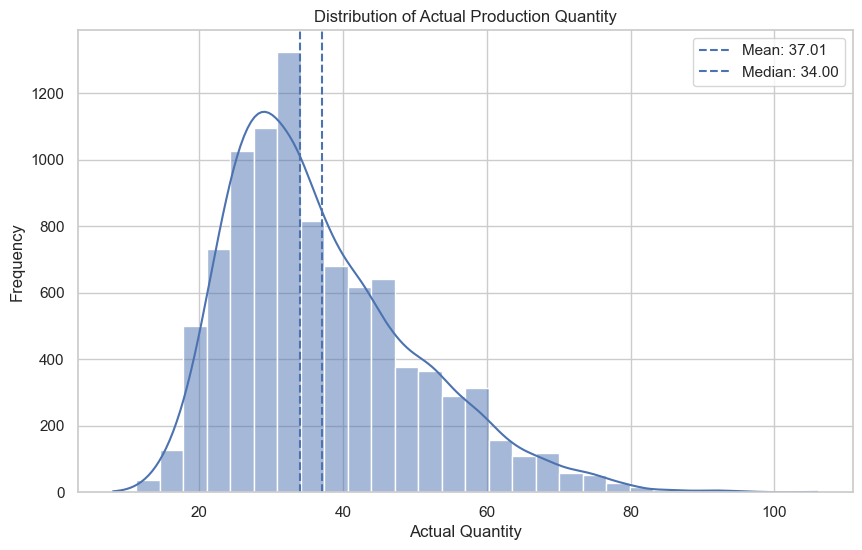

In [13]:
# Distribution of Actual Quantity

plt.figure(figsize=(10, 6))

ax = sns.histplot(
    df['actual_qty'],
    bins=30,
    kde=True
)

mean_val = df['actual_qty'].mean()
median_val = df['actual_qty'].median()

plt.axvline(
    mean_val,
    linestyle='--',
    label=f'Mean: {mean_val:.2f}'
)

plt.axvline(
    median_val,
    linestyle='--',
    label=f'Median: {median_val:.2f}'
)

plt.title('Distribution of Actual Production Quantity')
plt.xlabel('Actual Quantity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

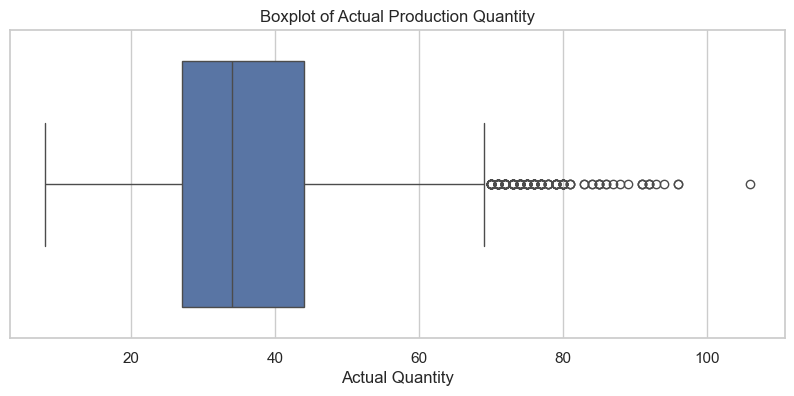

In [14]:
# Boxplot of Actual Quantity

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df['actual_qty']
)

plt.title('Boxplot of Actual Production Quantity')
plt.xlabel('Actual Quantity')
plt.show()

### 3.3 Log-transform check
Checks whether a log transformation would make the distribution noticeably more symmetric.


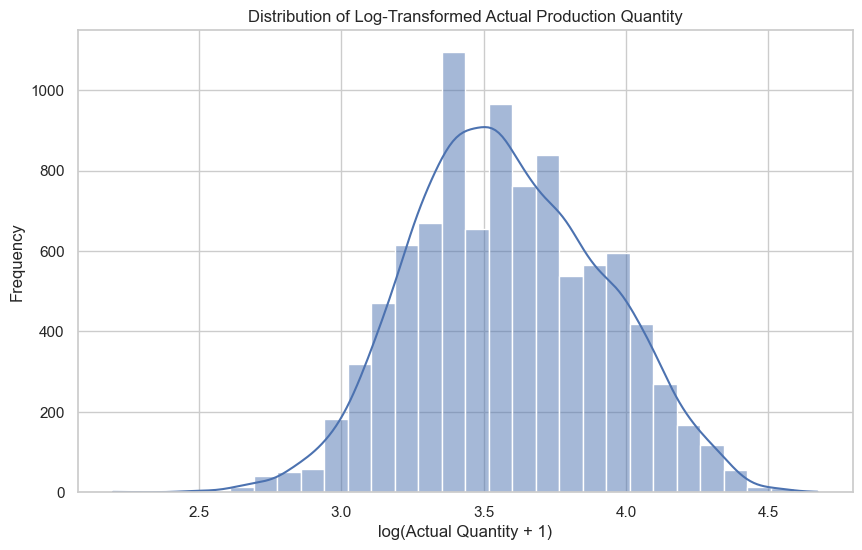

In [15]:
# Log-transformed target distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    np.log1p(df['actual_qty']),
    bins=30,
    kde=True
)

plt.title('Distribution of Log-Transformed Actual Production Quantity')
plt.xlabel('log(Actual Quantity + 1)')
plt.ylabel('Frequency')
plt.show()

---
## 4. Temporal Patterns
### 4.1 Weekly trend


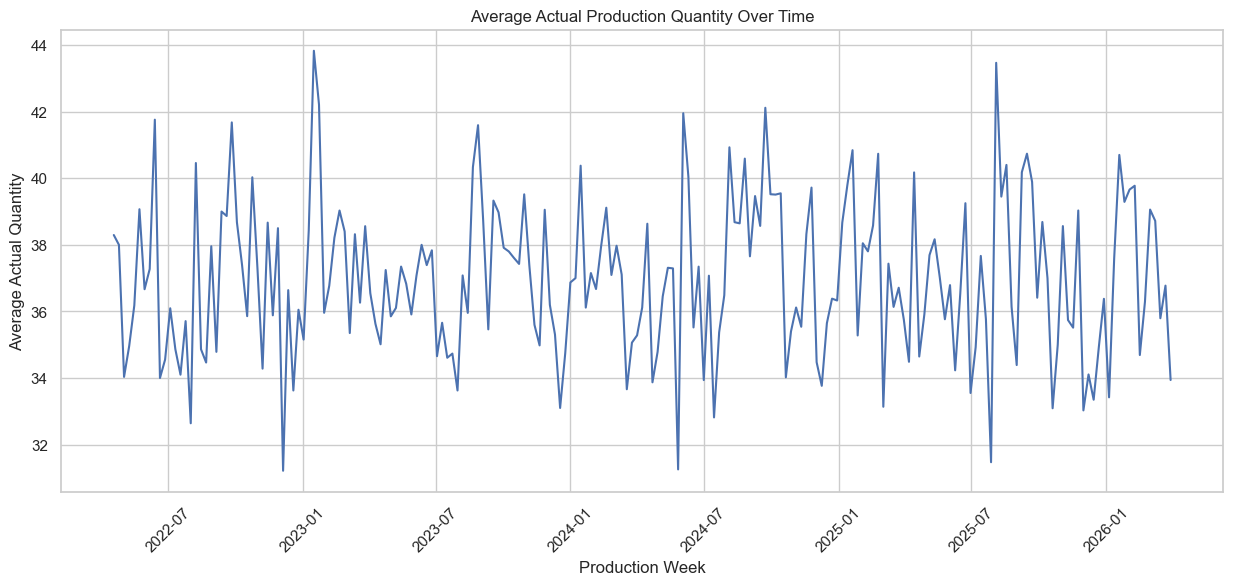

In [16]:
weekly_production = (
    df.groupby('week_start_date')['actual_qty']
      .mean()
      .reset_index()
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=weekly_production,
    x='week_start_date',
    y='actual_qty'
)

plt.title('Average Actual Production Quantity Over Time')
plt.xlabel('Production Week')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=45)
plt.show()

### 4.2 By financial month


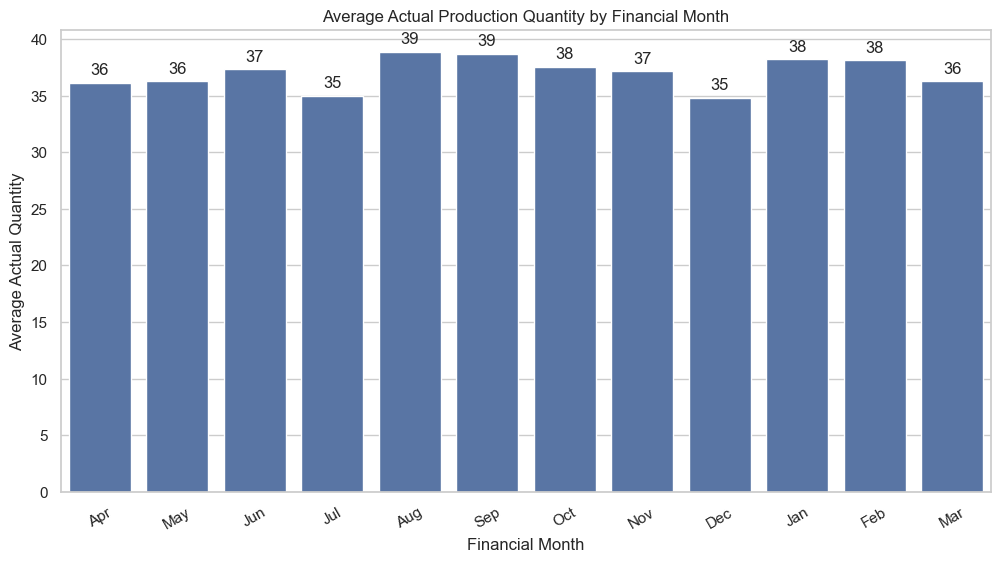

In [17]:
month_order = [
    'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep',
    'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar'
]

monthly_production = (
    df.groupby('financial_month')['actual_qty']
      .mean()
      .reindex(month_order)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=monthly_production.index,
    y=monthly_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Financial Month')
plt.xlabel('Financial Month')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=30)
plt.show()

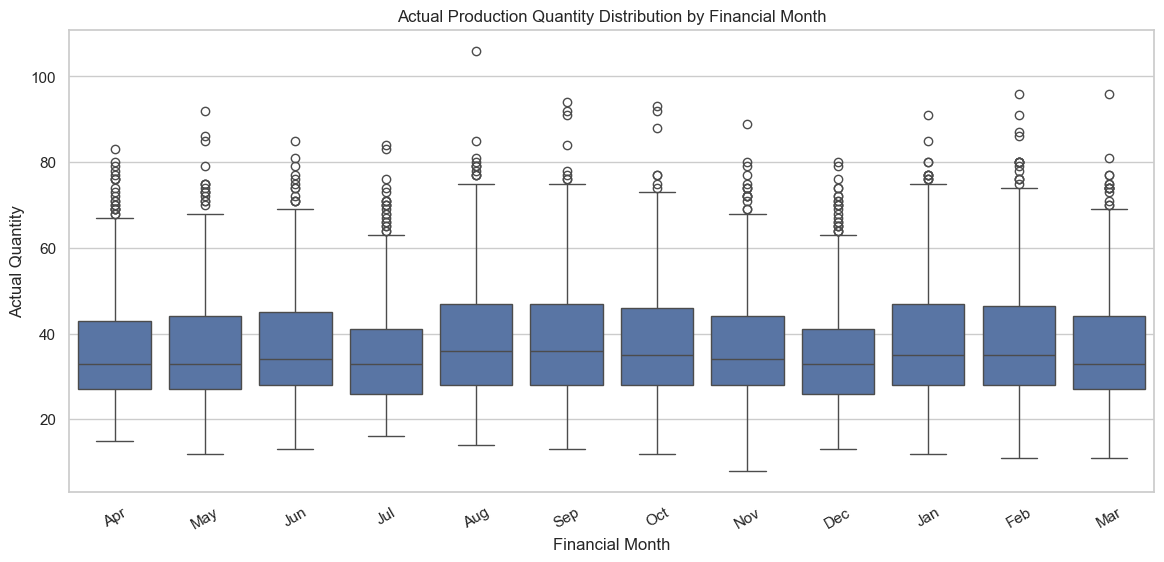

In [18]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x='financial_month',
    y='actual_qty',
    order=month_order
)

plt.title('Actual Production Quantity Distribution by Financial Month')
plt.xlabel('Financial Month')
plt.ylabel('Actual Quantity')
plt.xticks(rotation=30)
plt.show()

### 4.3 By financial year


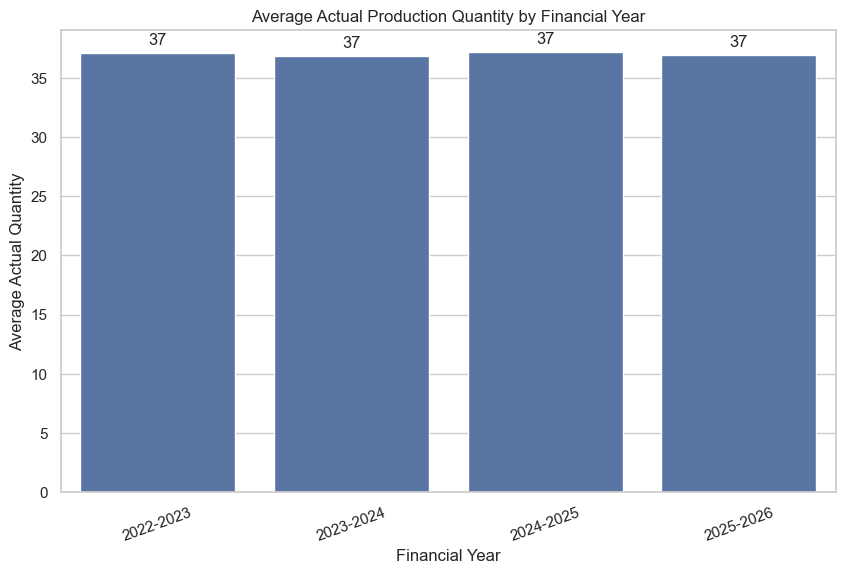

In [19]:
year_production = (
    df.groupby('financial_year')['actual_qty']
      .mean()
      .sort_index()
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=year_production.index,
    y=year_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Financial Year')
plt.xlabel('Financial Year')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=20)
plt.show()

### 4.4 By week number and week of month


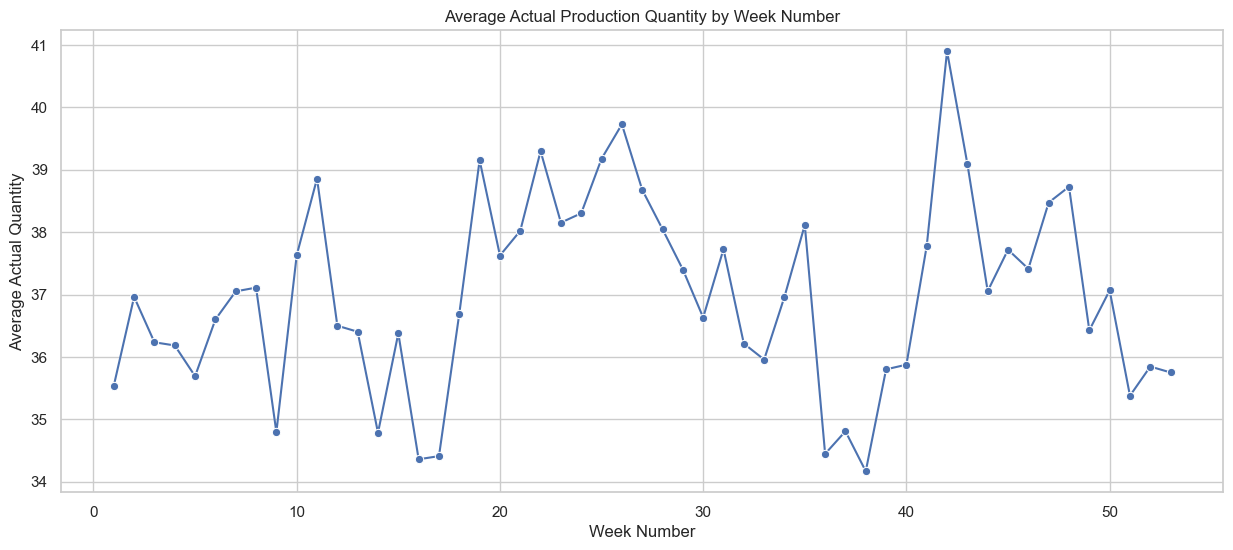

In [20]:
week_production = (
    df.groupby('week_no')['actual_qty']
      .mean()
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    x=week_production.index,
    y=week_production.values,
    marker='o'
)

plt.title('Average Actual Production Quantity by Week Number')
plt.xlabel('Week Number')
plt.ylabel('Average Actual Quantity')
plt.show()

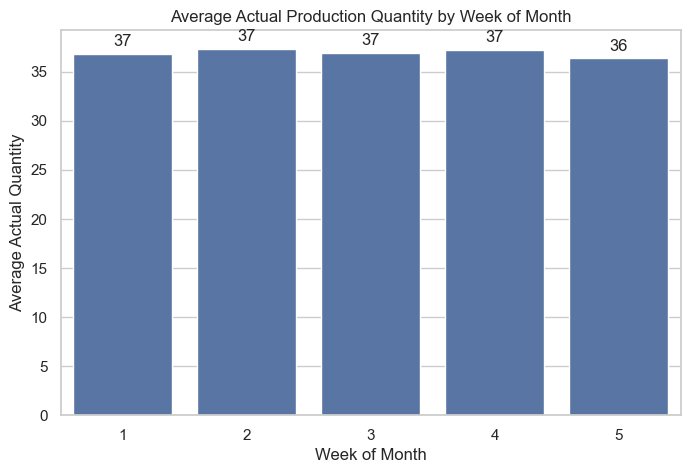

In [21]:
week_month_production = (
    df.groupby('week_of_month')['actual_qty']
      .mean()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=week_month_production.index,
    y=week_month_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Week of Month')
plt.xlabel('Week of Month')
plt.ylabel('Average Actual Quantity')
plt.show()

---
## 5. Categorical Drivers
### 5.1 Average actual quantity by category
`financial_year` and `financial_month` are already covered in Section 4, so they are not repeated here.


In [22]:
categorical_features = [
    'factory_unit',
    'product_family',
    'size_id',
    'grade',
    'order_category',
    'bottleneck_flag'
]

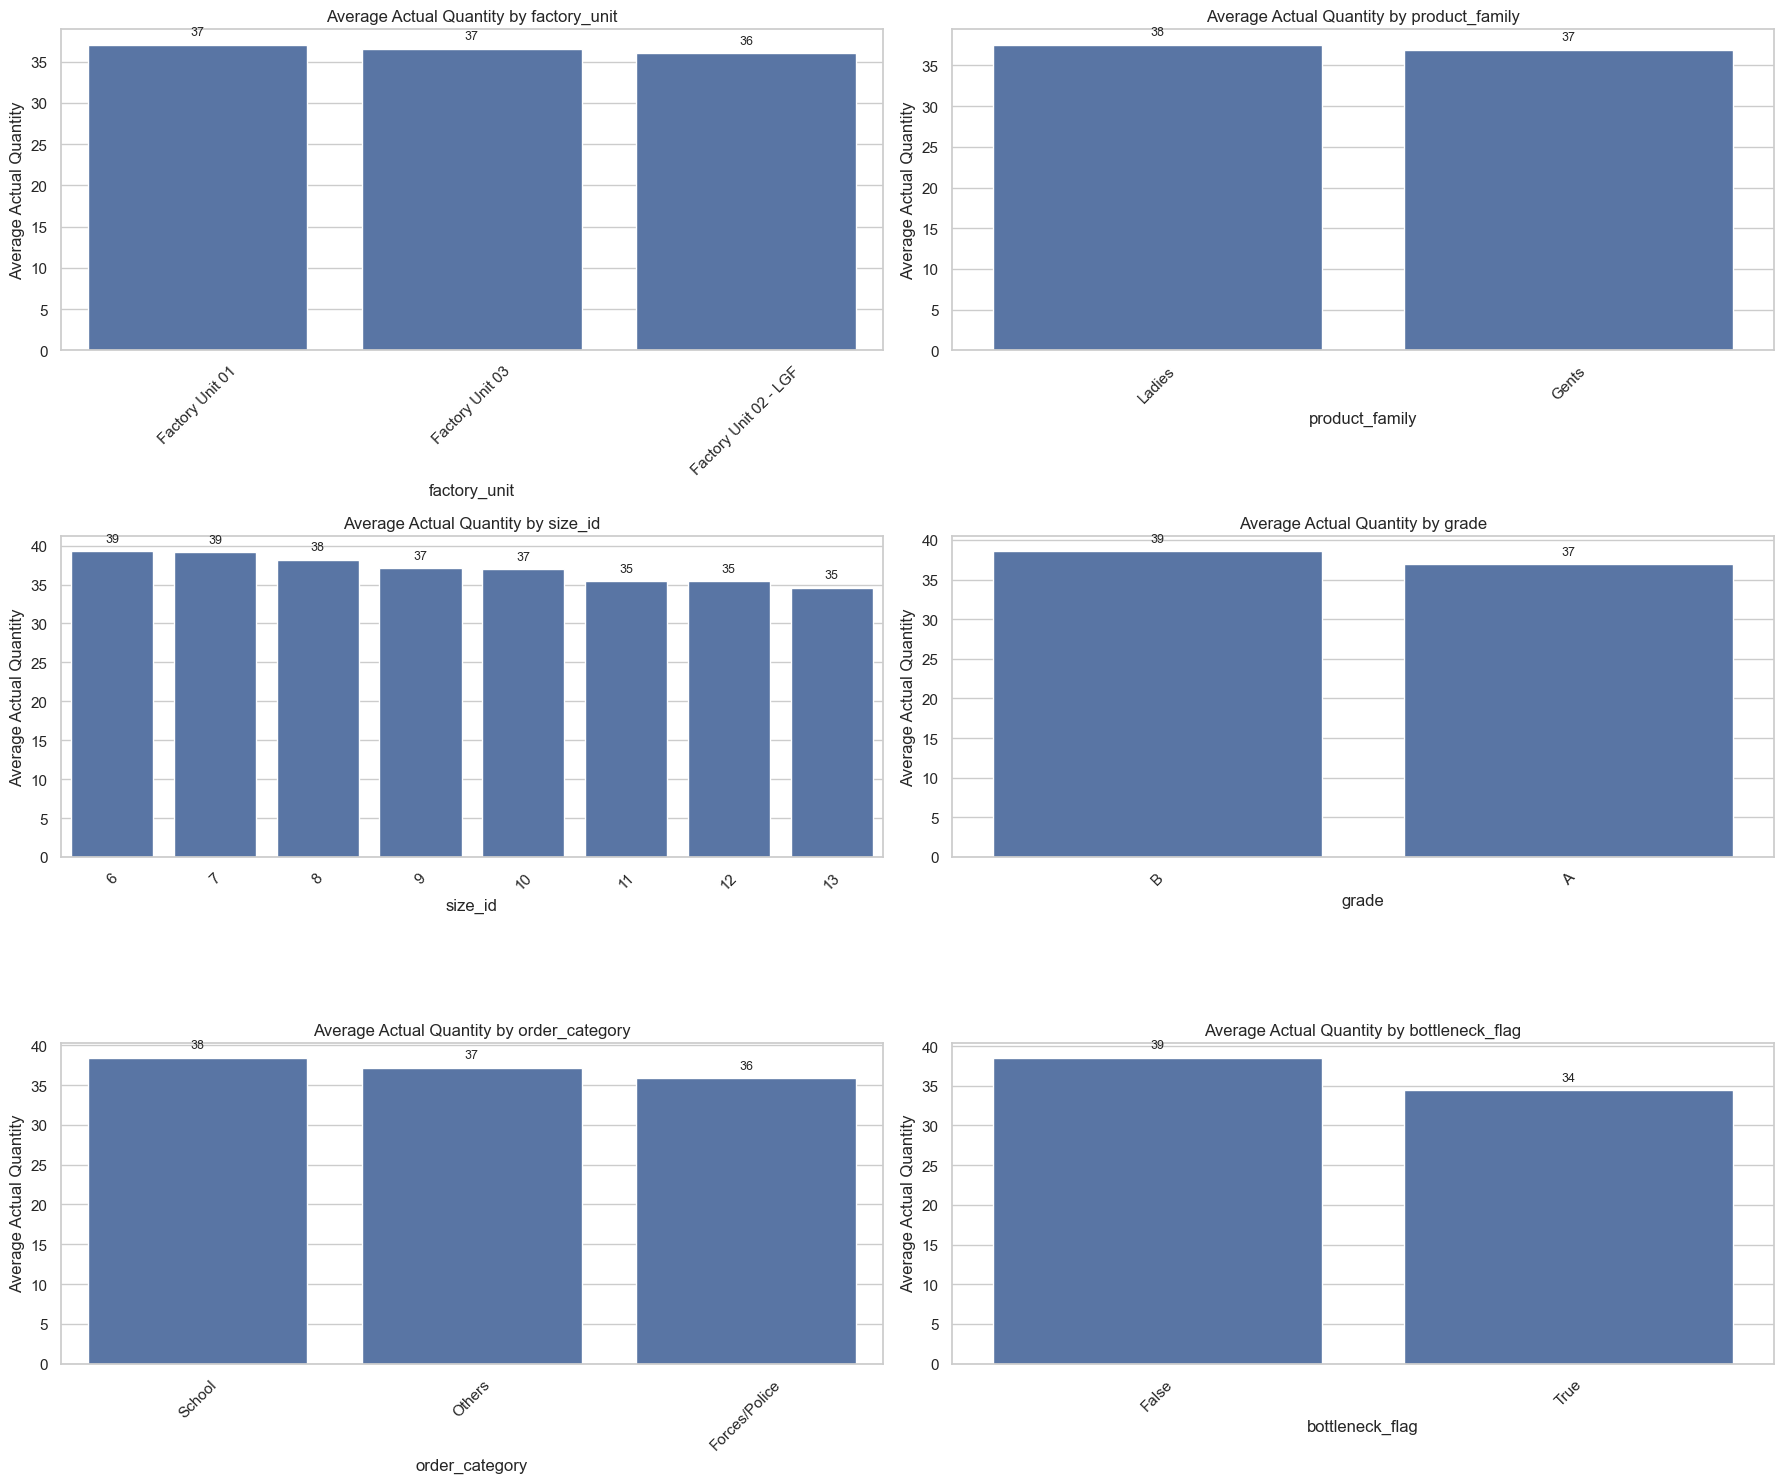

In [23]:
n_features = len(categorical_features)

n_cols = 2
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, categorical_features):

    summary = (
        df.groupby(feature)['actual_qty']
          .mean()
          .sort_values(ascending=False)
    )

    sns.barplot(
        x=summary.index.astype(str),
        y=summary.values,
        ax=ax
    )

    for p in ax.patches:
        ax.annotate(
            f'{p.get_height():.0f}',
            (p.get_x() + p.get_width() / 2.,
             p.get_height()),
            ha='center',
            va='center',
            xytext=(0, 9),
            textcoords='offset points',
            fontsize=9
        )

    ax.set_title(
        f'Average Actual Quantity by {feature}'
    )

    ax.set_xlabel(feature)
    ax.set_ylabel('Average Actual Quantity')
    ax.tick_params(axis='x', rotation=45)

for ax in axes[n_features:]:
    ax.remove()

plt.tight_layout()
plt.show()

### 5.2 Item-level analysis



In [24]:
# Item-level analysis

item_summary = (
    df.groupby('item_name')['actual_qty']
      .agg(['mean', 'count'])
      .sort_values('count', ascending=False)
)

item_summary.head(20)

,mean,count
item_name,,
DIYANA - L - BROWN,37.534884,43
ROGGER - L - BLACK,35.900000,40
BINOLI - BROWN,35.131579,38
D 90 - L - WHITE,37.702703,37
DI SAFETY 551 - L - BROWN,34.810811,37
D 707 - L - BROWN,32.756757,37
D 707 - L - BLACK,32.277778,36
ROMI - L - BLACK,42.694444,36
AYOMI (VAST) - L - BEIGE,39.714286,35


Highest and lowest average production among items with at least 10 observations.

Most items appear only a handful of times across 207 weeks


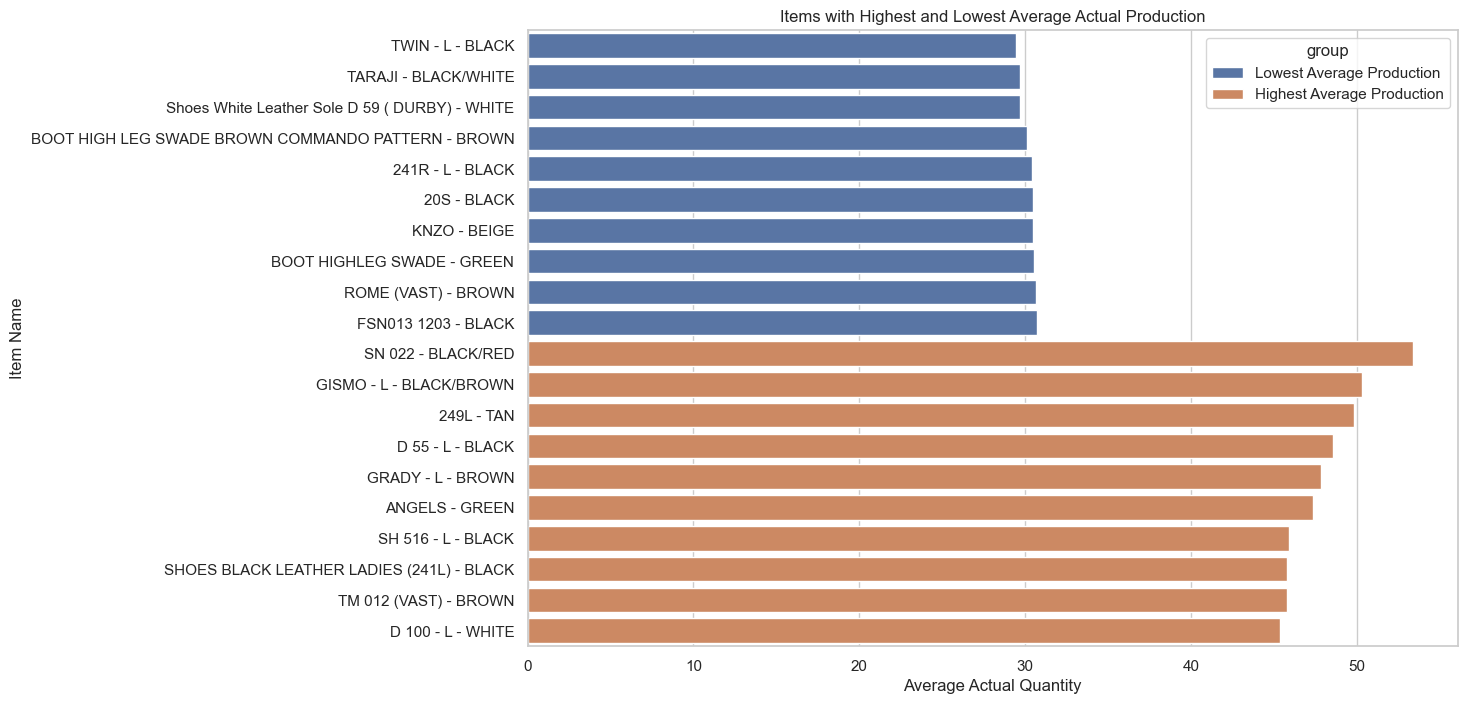

In [25]:
# Consider items with at least 10 observations

item_filtered = item_summary[
    item_summary['count'] >= 10
]

top_items = (
    item_filtered
    .sort_values('mean', ascending=False)
    .head(10)
)

bottom_items = (
    item_filtered
    .sort_values('mean', ascending=True)
    .head(10)
)

item_plot = pd.concat([
    bottom_items.assign(
        group='Lowest Average Production'
    ),
    top_items.assign(
        group='Highest Average Production'
    )
])

plt.figure(figsize=(12, 8))

sns.barplot(
    data=item_plot,
    x='mean',
    y=item_plot.index,
    hue='group'
)

plt.title(
    'Items with Highest and Lowest Average Actual Production'
)

plt.xlabel('Average Actual Quantity')
plt.ylabel('Item Name')
plt.show()

### 5.3 Distribution by factory unit and size


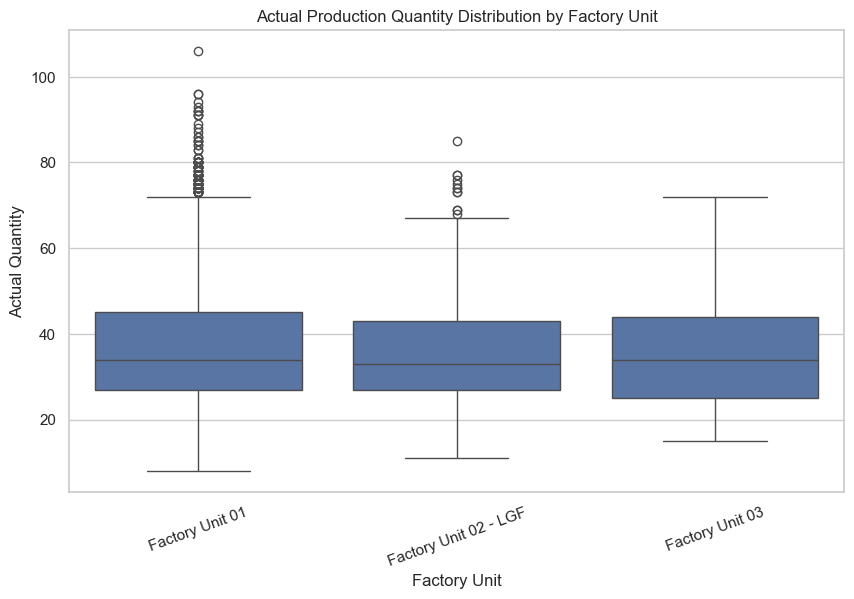

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='factory_unit',
    y='actual_qty'
)

plt.title('Actual Production Quantity Distribution by Factory Unit')
plt.xlabel('Factory Unit')
plt.ylabel('Actual Quantity')
plt.xticks(rotation=20)
plt.show()

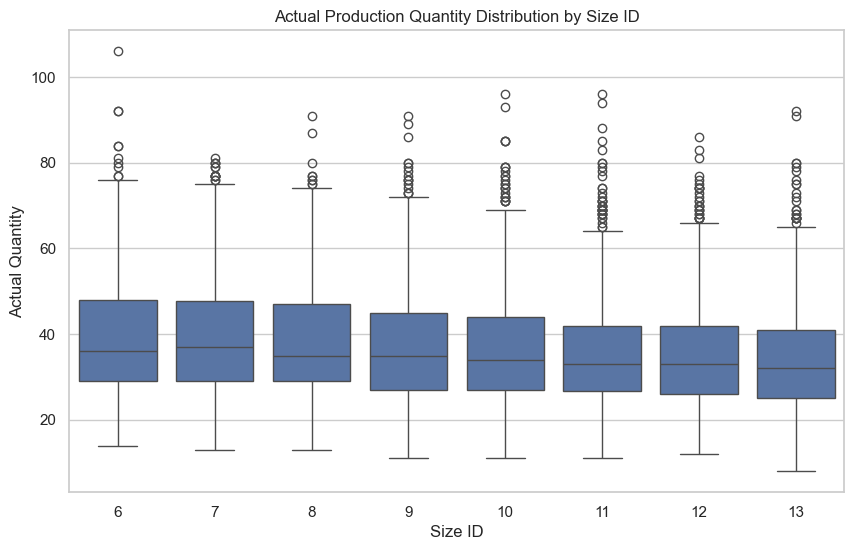

In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='size_id',
    y='actual_qty'
)

plt.title('Actual Production Quantity Distribution by Size ID')
plt.xlabel('Size ID')
plt.ylabel('Actual Quantity')
plt.show()

### 5.4 Bottleneck flag


In [28]:
bottleneck_summary = (
    df.groupby('bottleneck_flag')['actual_qty']
      .agg(['count', 'mean', 'median', 'std'])
)

bottleneck_summary

,count,mean,median,std
bottleneck_flag,,,,
False,5983,38.507271,36.0,13.127614
True,3512,34.464692,32.0,12.518350


---
## 6. Numerical Drivers & Correlation
### 6.1 Numerical features under analysis
`machine_capacity_per_day` is left out (constant, so correlation is undefined). The remaining planning-style columns that earlier dataset versions contained (`monthly_plan_qty`, `labor_hours`, `overtime_hours`, `takt_time_mins`) do not exist in this dataset.


In [29]:
numeric_features = [
    'planned_qty',
    'rate',
    'no_of_workers',
    'working_hours',
    'machine_count',
    'total_duration_per_shoe_mins',
    'week_no',
    'week_of_month'
]

print("Numerical features used for EDA:")
print(numeric_features)

Numerical features used for EDA:
['planned_qty', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'total_duration_per_shoe_mins', 'week_no', 'week_of_month']


### 6.2 Average actual quantity across feature deciles


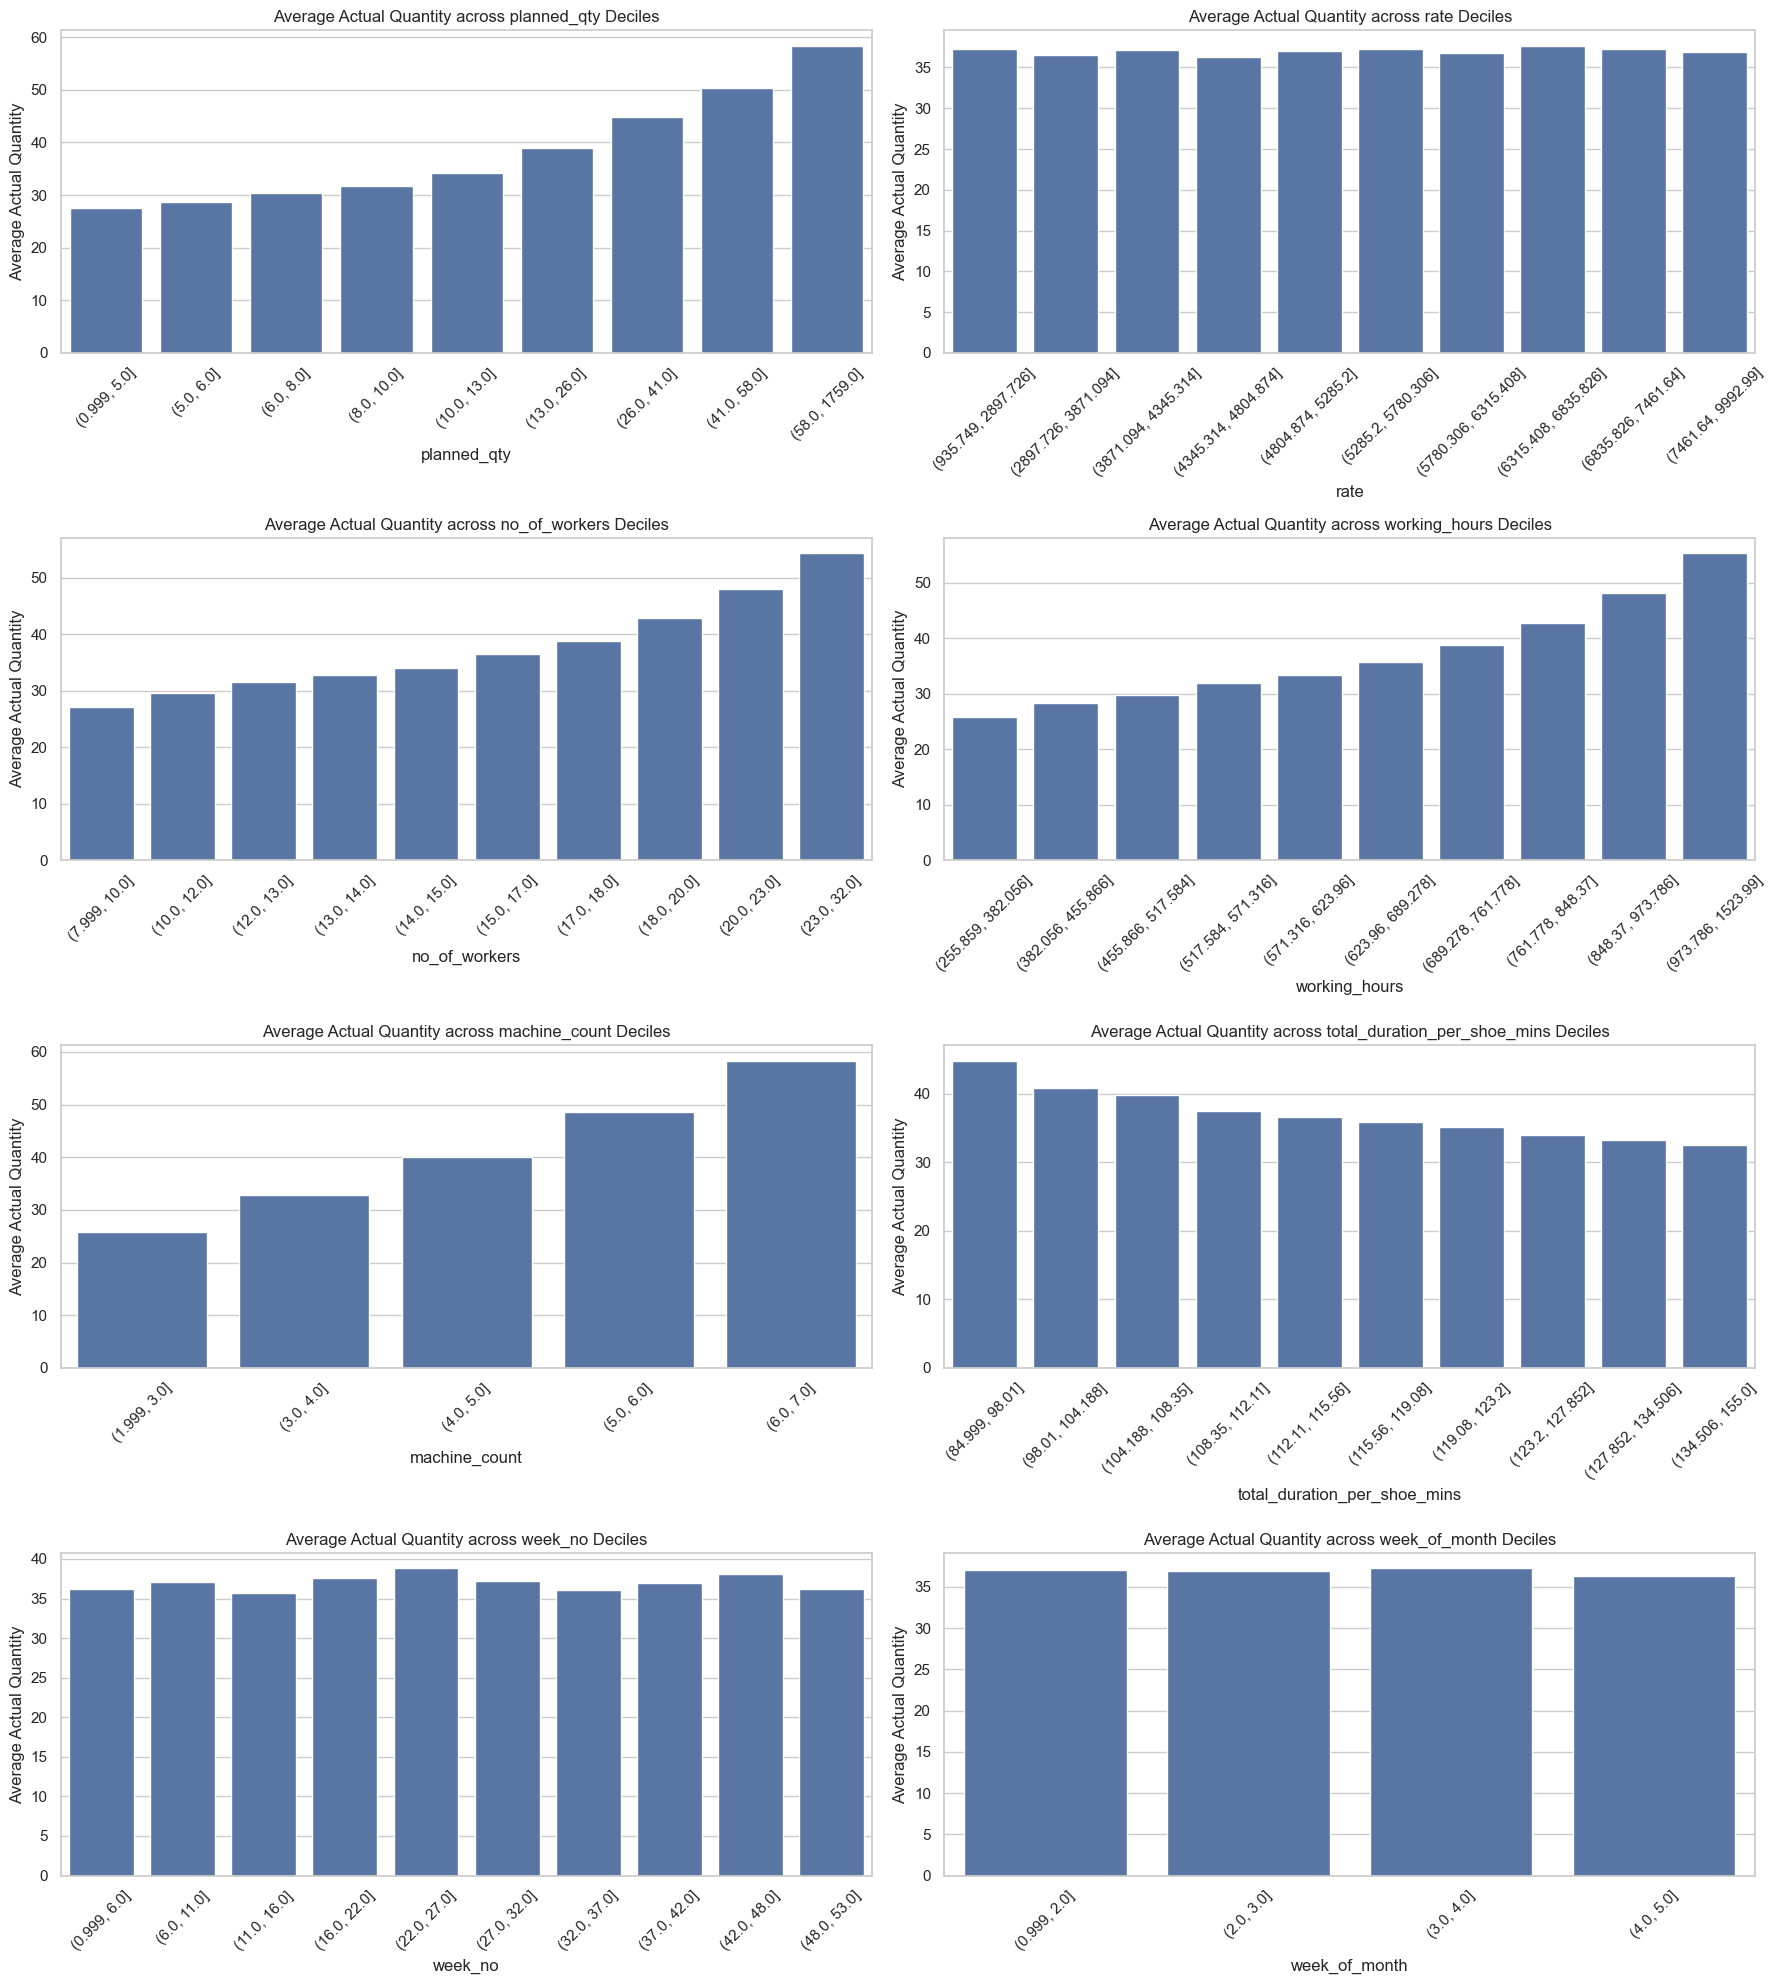

In [30]:
n_features = len(numeric_features)

n_cols = 2
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, numeric_features):

    temp = df[
        [feature, 'actual_qty']
    ].dropna().copy()

    try:
        temp['bin'] = pd.qcut(
            temp[feature],
            q=10,
            duplicates='drop'
        )

        summary = (
            temp.groupby(
                'bin',
                observed=True
            )['actual_qty']
            .mean()
        )

        sns.barplot(
            x=summary.index.astype(str),
            y=summary.values,
            ax=ax
        )

        ax.set_title(
            f'Average Actual Quantity across {feature} Deciles'
        )

        ax.set_xlabel(feature)
        ax.set_ylabel('Average Actual Quantity')

        ax.tick_params(
            axis='x',
            rotation=45
        )

    except ValueError:

        ax.scatter(
            temp[feature],
            temp['actual_qty'],
            alpha=0.35
        )

        ax.set_title(
            f'{feature} vs Actual Quantity'
        )

        ax.set_xlabel(feature)
        ax.set_ylabel('Actual Quantity')

for ax in axes[n_features:]:
    ax.remove()

plt.tight_layout()
plt.show()

### 6.3 Correlation with the target


In [31]:
# Numerical features selected for correlation analysis (target included)
correlation_features = numeric_features
correlation_columns = correlation_features + ['actual_qty']

correlation_matrix = df[correlation_columns].corr()

print("Variables included in correlation analysis:")
print(correlation_columns)

Variables included in correlation analysis:
['planned_qty', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'total_duration_per_shoe_mins', 'week_no', 'week_of_month', 'actual_qty']


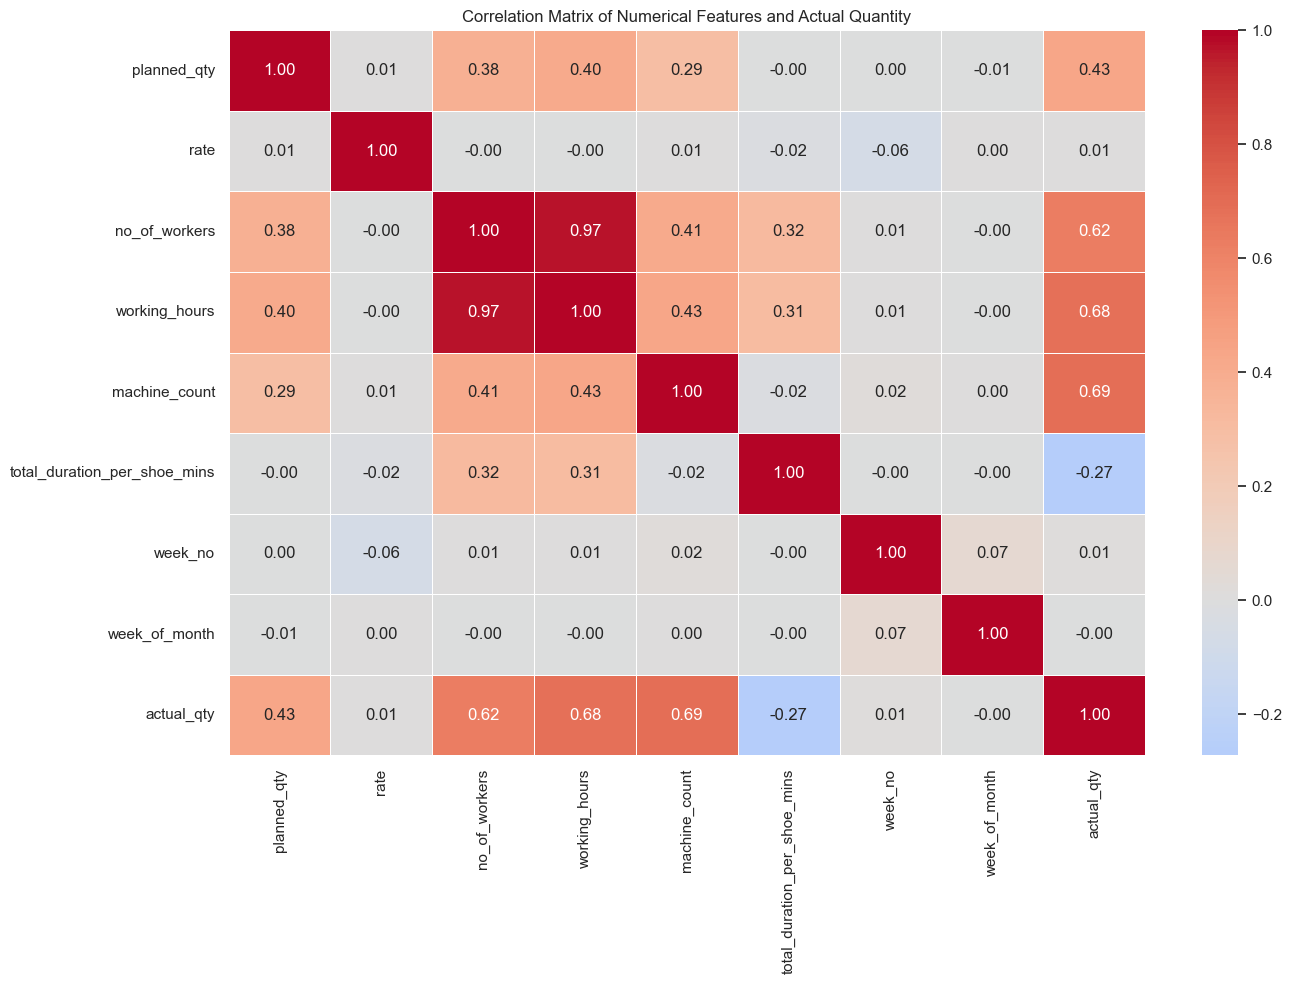

In [32]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features and Actual Quantity")
plt.tight_layout()
plt.show()

Correlation of each numerical feature with `actual_qty`:


In [33]:
target_correlations = (
    correlation_matrix['actual_qty']
    .drop('actual_qty')
    .sort_values(ascending=False)
)

print("Correlation of Numerical Features with Actual Quantity:")
display(target_correlations.to_frame(name='Correlation with actual_qty'))

Correlation of Numerical Features with Actual Quantity:


,Correlation with actual_qty
machine_count,0.689623
working_hours,0.682933
no_of_workers,0.623795
planned_qty,0.431519
week_no,0.014598
rate,0.006793
week_of_month,-0.001624
total_duration_per_shoe_mins,-0.272027


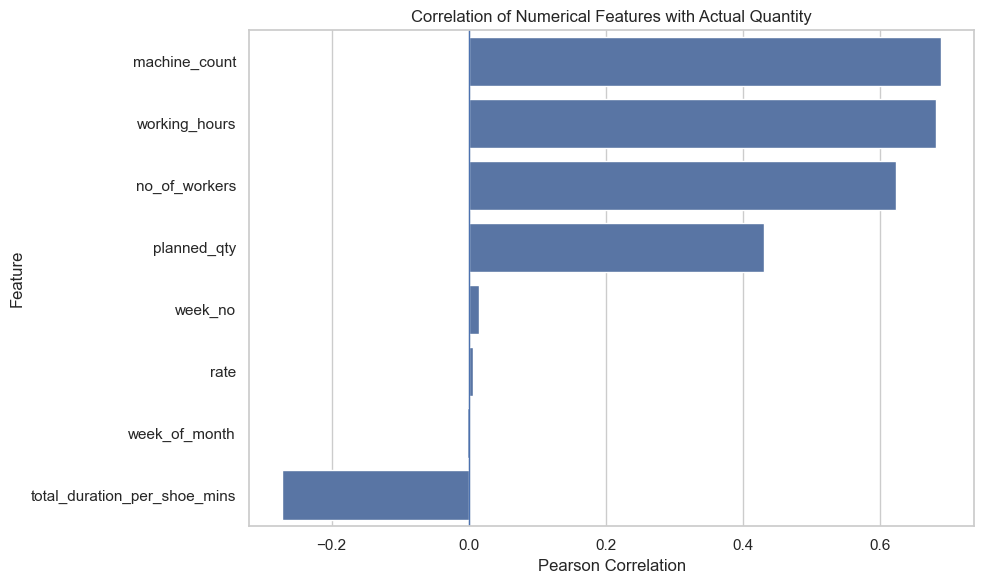

In [34]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_correlations.values,
    y=target_correlations.index
)

plt.axvline(0, linewidth=1)

plt.title("Correlation of Numerical Features with Actual Quantity")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### 6.4 Multicollinearity among predictors
Predictor pairs with absolute correlation ≥ 0.80. `no_of_workers` and `working_hours` are almost perfectly correlated (≈0.97), so they carry nearly the same information.


In [35]:
# Correlation among predictor variables only
predictor_corr = df[correlation_features].corr().abs()

# Select upper triangle of correlation matrix
upper_triangle = predictor_corr.where(
    np.triu(
        np.ones(predictor_corr.shape),
        k=1
    ).astype(bool)
)

# Identify pairs with correlation greater than 0.80
high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Absolute Correlation'
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs['Absolute Correlation'] >= 0.80
].sort_values(
    'Absolute Correlation',
    ascending=False
)

print("Highly correlated predictor pairs (|r| >= 0.80):")

display(high_corr_pairs)

Highly correlated predictor pairs (|r| >= 0.80):


,Feature 1,Feature 2,Absolute Correlation
13,no_of_workers,working_hours,0.969682


---
## 7. Key EDA Findings

- **Data quality:** 9,495 rows, no missing values, no duplicates, no zero/negative quantities. `machine_capacity_per_day` is constant (200) and carries no information.
- **Target (`actual_qty`):** ranges from 8 to 106, mean ≈ 37, median 34 — fairly symmetric with a mild right tail, so no transformation is required.
- **Planned vs. actual scale:** `planned_qty` is heavily right-skewed (median 10, 75th percentile 34, mean ≈ 38) while `actual_qty` is concentrated around 27–44. The two are only moderately correlated (≈0.43), and `production_gap_qty` has a negative median — in most rows actual output exceeds the planned figure.
- **Strongest numerical drivers:** `machine_count` (≈0.69), `working_hours` (≈0.68) and `no_of_workers` (≈0.62) rise together with output; `total_duration_per_shoe_mins` is negatively related (≈−0.27). `rate`, `week_no` and `week_of_month` show essentially no relationship.
- **Redundancy:** `no_of_workers` and `working_hours` are ≈0.97 correlated; one of them is effectively redundant.
- **Categorical drivers are weak:** average output differs only slightly across factory units, product family, grade, size and order category (roughly 35–39 units). The clearest categorical effect is `bottleneck_flag` (≈34 for flagged rows vs ≈39 for non-flagged).
- **Temporal effects are mild:** financial years are almost identical (≈37), and monthly averages vary only between ≈35 (Jul, Dec) and ≈39 (Aug).
- **Item level:** 370 distinct items, most with few observations — too sparse to use `item_name` directly.
- **Sample imbalance:** Factory Unit 01 has 8,921 rows, Factory Unit 02 – LGF 525 and Factory Unit 03 only 49.
